# Detection v5: detection v4's detector against the v8 adversary

The detector is detection v4's, unchanged:

- channels: closure, round trip (W = 50, 100, 200) and same-pair repeat (W = 20, 50, 200);
- each channel propagated over the counterparty graph;
- a control-null fusion, floor 0.5, and thresholds calibrated to a pooled control FPR of 1%.

The data are the two `washtrade/v8` sweeps at 200 seeds (28,000 runs).

- **`adversary`**: v7's full evasive group (pool 96, Q in 1..4, residual, camouflage), now with
  - **edge order**: interleaved edges, so a pair no longer trades several units in a row;
  - **pipeline** D: D rounds open at once, so each wallet holds a position about D times longer
    while the group stays flat;
  - a **slower wash rate** (0.0125 instead of 0.05).
- **`honest`**: the same backgrounds with multi-unit honest orders (1..4 units, `_mu4`), crossed
  with v7 execution, block execution and the strongest v8 execution.

Thresholds are recalibrated on each v8 background's 200 control runs. For the four standard
backgrounds they equal detection v4's: same runs, same thresholds (smoke check B).

This notebook only reads results. Set `RUN_DETECTION = True` to rerun detection, which takes about
12 minutes with 15 jobs.

In [1]:
import os
import subprocess
import sys
import time
from pathlib import Path


def _find_root(start):
    for p in [start, *start.parents]:
        if (p / "marketsim").is_dir() and (p / "capstone codes").is_dir():
            return p
    raise RuntimeError("repository root not found above " + str(start))


ROOT = _find_root(Path.cwd().resolve())
for p in (str(ROOT), str(ROOT / "capstone codes")):
    if p not in sys.path:
        sys.path.insert(0, p)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from washtrade.v8 import design as D
from washtrade.v8 import generate as G
from detection.v5 import experiment as X
from detection.v4.fusion import MAIN_FLOOR

DET5 = ROOT / "capstone codes" / "detection" / "v5"

## Configuration

In [2]:
# Folder holding ds_v8_<sweep>/. Set the WASH_V8_DATA environment variable, or edit this line.
DATA = Path(os.environ.get("WASH_V8_DATA") or (ROOT / "capstone codes" / "washtrade" / "v8" / "data"))
RUN_DETECTION = False                 # True = smoke test + detection on both sweeps (~12 min)
JOBS = max(1, (os.cpu_count() or 2) - 1)
SWEEPS = list(D.SWEEPS)
missing = [sw for sw in SWEEPS if not (Path(G.dataset_root(sw, out_dir=str(DATA))) / "manifest.csv").exists()]
print("sweeps:", SWEEPS, "| missing datasets:", missing or "none")

sweeps: ['adversary', 'honest'] | missing datasets: none


## 1. Smoke test and detection (only if `RUN_DETECTION`)

In [3]:
if RUN_DETECTION:
    res = subprocess.run([sys.executable, str(DET5 / "run_smoke.py")], cwd=ROOT,
                         capture_output=True, text=True, encoding="utf-8")
    print(res.stdout.splitlines()[-1])
    if res.returncode != 0:
        raise RuntimeError("smoke test failed:\n" + res.stdout[-2000:])
    t0 = time.time()
    X.run_all(SWEEPS, jobs=JOBS, data=str(DATA))
    print(f"detection done in {(time.time() - t0) / 60:.0f} min")
else:
    print("RUN_DETECTION is False: reading existing results")

RUN_DETECTION is False: reading existing results


## 2. Load results

In [4]:
COST = ["run_id", "repeat_share_50", "hold_mean", "open_unit_share", "rounds_completed_share",
        "wash_volume_rate", "zero_returns_per_used_wallet"]


def load(sw):
    r = pd.read_csv(Path(X.out_dir(sw, str(DATA))) / "results.csv")
    m = pd.read_csv(Path(G.dataset_root(sw, out_dir=str(DATA))) / "manifest.csv",
                    usecols=lambda c: c in COST)
    return r.merge(m, on="run_id", how="left")


R = {sw: load(sw) for sw in SWEEPS}
TH = pd.read_csv(DATA / "detection_v5_thresholds.csv")
print({sw: f"{R[sw]['run_id'].nunique()} runs x {R[sw]['method'].nunique()} methods" for sw in SWEEPS})

BG4 = ["thin", "thick", "active", "active_dense"]
COLOR = {"thin": "#2a78d6", "thick": "#eb6834", "active_thin": "#eda100", "active": "#1baf7a",
         "active_dense": "#e87ba4"}                # same as detection v2-v4
MARKER = {"thin": "o", "thick": "s", "active_thin": "D", "active": "^", "active_dense": "v"}
EXEC = [("sequential", 1), ("interleaved", 1), ("sequential", 4), ("interleaved", 4),
        ("sequential", 8), ("interleaved", 8)]
EXEC_LABEL = {e: f"{e[0][:5]}, D={e[1]}" for e in EXEC}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titlesize": 11, "axes.labelsize": 10,
    "legend.frameon": False, "lines.linewidth": 2, "lines.markersize": 6,
})


def pooled(df, by):
    # Volume-pooled recall, precision and FPR (sum over runs, then divide), plus mean AP.
    g = df.groupby(by)
    s = g[["trade_tp", "trade_fp", "trade_pos", "trade_neg"]].sum()
    out = pd.DataFrame({"recall": s["trade_tp"] / s["trade_pos"],
                        "precision": s["trade_tp"] / (s["trade_tp"] + s["trade_fp"]),
                        "fpr": s["trade_fp"] / s["trade_neg"]})
    out["ap"] = g["trade_ap"].mean()
    return out


def heat(ax, piv, vmin=0, vmax=1, cmap="Blues", fmt="{:.2f}"):
    ax.imshow(piv.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.grid(False)
    ax.set_xticks(range(piv.shape[1]), piv.columns, rotation=0)
    ax.set_yticks(range(piv.shape[0]), piv.index)
    for (i, j), v in np.ndenumerate(piv.values):
        if np.isfinite(v):
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9,
                    color="white" if (v - vmin) / (vmax - vmin) > 0.6 else "#0b0b0b")

{'adversary': '20000 runs x 12 methods', 'honest': '8000 runs x 12 methods'}


## 3. Thresholds on the multi-unit backgrounds

Effective thresholds at floor 0.5. For single channels this is max(θ, 0.5) on the raw score;
for v4 it is on the fused scale. With multi-unit honest orders, the closure channel cannot reach
a 1% control FPR in the active markets (θ = 1 or above), so it flags nothing there. The fused
detector still calibrates, through the other channels.

In [5]:
th = TH[TH["floor"] == MAIN_FLOOR].copy()
single = th["method"] != "v4"
th["theta_eff"] = np.where(single, np.maximum(th["theta_1"], MAIN_FLOOR), th["theta_1"])
order = BG4 + [f"{b}_mu4" for b in BG4]
display(th[th["method"].isin(["closure", "roundtrip_100", "roundtrip_200", "repeat_50", "repeat_200", "v4"])]
        .pivot(index="method", columns="background", values="theta_eff")[order].round(3))

background,thin,thick,active,active_dense,thin_mu4,thick_mu4,active_mu4,active_dense_mu4
method,,,,,,,,
closure,0.840,0.809,0.980,0.963,0.845,0.887,1.000,1.000
repeat_200,0.623,0.615,0.500,0.500,0.641,0.517,0.500,0.500
repeat_50,0.500,0.609,0.500,0.500,0.536,0.514,0.500,0.500
roundtrip_100,0.517,0.570,0.642,0.643,0.534,0.589,0.579,0.575
roundtrip_200,0.510,0.638,0.814,0.809,0.518,0.667,0.783,0.781
v4,0.996,0.997,0.997,0.997,0.997,0.997,0.995,0.995


## 4. The v8 adversary: recall of v4 by execution (gap 0)

`adversary` sweep, gap 0. Rows are execution settings; columns are backgrounds. Recall is at the
calibrated threshold, pooled over 200 seeds. The top row ("seque, D=1") is v7's execution, the
"all four tactics" adversary of detection v4. Left: wash rate 0.05. Right: 0.0125.

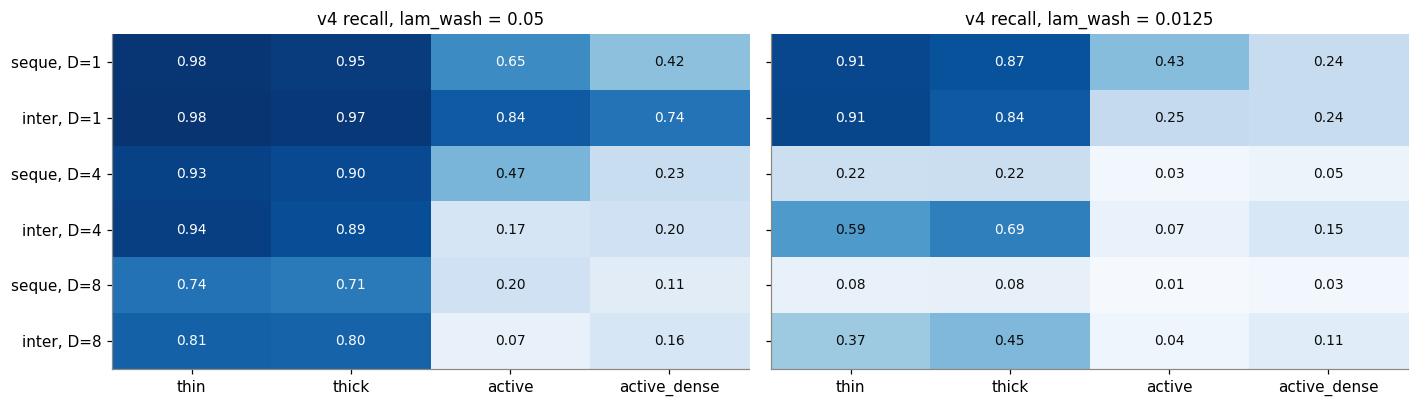

In [6]:
ad = R["adversary"]
aw = ad[ad["f_scenario"] == "wash"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, lam in zip(axes, (0.05, 0.0125)):
    s = aw[(aw.f_gap == 0) & (aw.f_lam_wash == lam) & (aw.method == "v4")]
    p = pooled(s, ["f_edge_order", "f_pipeline", "background"])["recall"].unstack("background")[BG4]
    p = p.reindex(pd.MultiIndex.from_tuples(EXEC))
    p.index = [EXEC_LABEL[e] for e in EXEC]
    heat(ax, p)
    ax.set_title(f"v4 recall, lam_wash = {lam}")
axes[1].set_yticklabels([])
fig.tight_layout()

## 5. Which channel carries detection (active, gap 0, wash rate 0.05)

Recall by channel. Interleaving removes the same-pair bursts, so `repeat_50` falls, but each
wallet then undoes its position within one pass of the cycle, and `roundtrip_100` rises. A
pipeline stretches the holding time beyond every round-trip window and removes the bursts as
well. Only `repeat_200` survives, partly, and only with sequential edges.

In [7]:
CH = ["closure", "roundtrip_50", "roundtrip_100", "roundtrip_200", "repeat_20", "repeat_50", "repeat_200", "v4"]
for bg in ("active", "thick"):
    s = aw[(aw.f_gap == 0) & (aw.f_lam_wash == 0.05) & (aw.background == bg) & aw.method.isin(CH)]
    p = pooled(s, ["f_edge_order", "f_pipeline", "method"])["recall"].unstack("method")[CH]
    p = p.reindex(pd.MultiIndex.from_tuples(EXEC))
    p.index = [EXEC_LABEL[e] for e in EXEC]
    print(bg)
    display(p.round(2))

active


method,closure,roundtrip_50,roundtrip_100,roundtrip_200,repeat_20,repeat_50,repeat_200,v4
"seque, D=1",0.08,0.06,0.21,0.16,0.15,0.46,0.57,0.65
"inter, D=1",0.11,0.74,0.69,0.24,0.00,0.07,0.54,0.84
"seque, D=4",0.07,0.00,0.00,0.00,0.00,0.00,0.46,0.47
"inter, D=4",0.13,0.00,0.07,0.12,0.00,0.00,0.02,0.17
"seque, D=8",0.06,0.00,0.00,0.00,0.00,0.00,0.19,0.20
"inter, D=8",0.16,0.00,0.00,0.01,0.00,0.00,0.00,0.07


thick


method,closure,roundtrip_50,roundtrip_100,roundtrip_200,repeat_20,repeat_50,repeat_200,v4
"seque, D=1",0.69,0.12,0.45,0.81,0.28,0.71,0.78,0.95
"inter, D=1",0.83,0.88,0.92,0.89,0.00,0.12,0.76,0.97
"seque, D=4",0.62,0.00,0.00,0.03,0.00,0.00,0.71,0.90
"inter, D=4",0.82,0.00,0.24,0.77,0.00,0.00,0.03,0.89
"seque, D=8",0.48,0.00,0.00,0.00,0.00,0.00,0.34,0.71
"inter, D=8",0.83,0.00,0.00,0.16,0.00,0.00,0.00,0.80


## 6. What evasion costs the adversary

Each point is one `adversary` cell at gap 0, pooled over 200 seeds. The x axis shows the
adversary's cost, the y axis v4's recall.

- **Left: holding time.** The mean number of steps a wash wallet's unit stays open before it is
  undone.
- **Middle: open units.** The share of a wash wallet's units still open when the run ends.
- **Right: wash volume per 1000 steps.** This is what the scheme buys.

Marker fill: filled = wash rate 0.05, open = 0.0125.

repeat_share_50  hold_mean  \
f_lam_wash f_edge_order f_pipeline                               
0.0125     interleaved  1.0                    0.05     242.78   
                        4.0                    0.00     466.77   
                        8.0                    0.00     686.03   
           sequential   1.0                    0.49     379.33   
                        4.0                    0.00     730.79   
                        8.0                    0.00     728.51   
0.0500     interleaved  1.0                    0.48     172.04   
                        4.0                    0.01     249.19   
                        8.0                    0.00     334.48   
           sequential   1.0                    0.85     214.26   
                        4.0                    0.20     403.25   
                        8.0                    0.00     617.81   

                                    open_unit_share  rounds_completed_share  \
f_lam_wash f_edge_order f_pipeline                                            
0.0125     interleaved  1.0                    0.17                    0.76   
                        4.0                    0.23                    0.29   
                        8.0                    0.30                    0.14   
           sequential   1.0                    0.21                    0.76   
                        4.0                    0.40                    0.29   
                        8.0                    0.55                    0.14   
0.0500     interleaved  1.0                    0.15                    0.93   
                        4.0                    0.16                    0.74   
                        8.0                    0.19                    0.55   
           sequential   1.0                    0.16                    0.93   
                        4.0                    0.19                    0.74   
                        8.0                    0.24                    0.55   

                                    wash_volume_rate  
f_lam_wash f_edge_order f_pipeline                    
0.0125     interleaved  1.0                    11.85  
                        4.0                    12.09  
                        8.0                    12.15  
           sequential   1.0                    11.80  
                        4.0                    12.06  
                        8.0                    12.14  
0.0500     interleaved  1.0                    44.92  
                        4.0                    45.88  
                        8.0                    46.30  
           sequential   1.0                    44.78  
                        4.0                    45.76  
                        8.0                    46.18

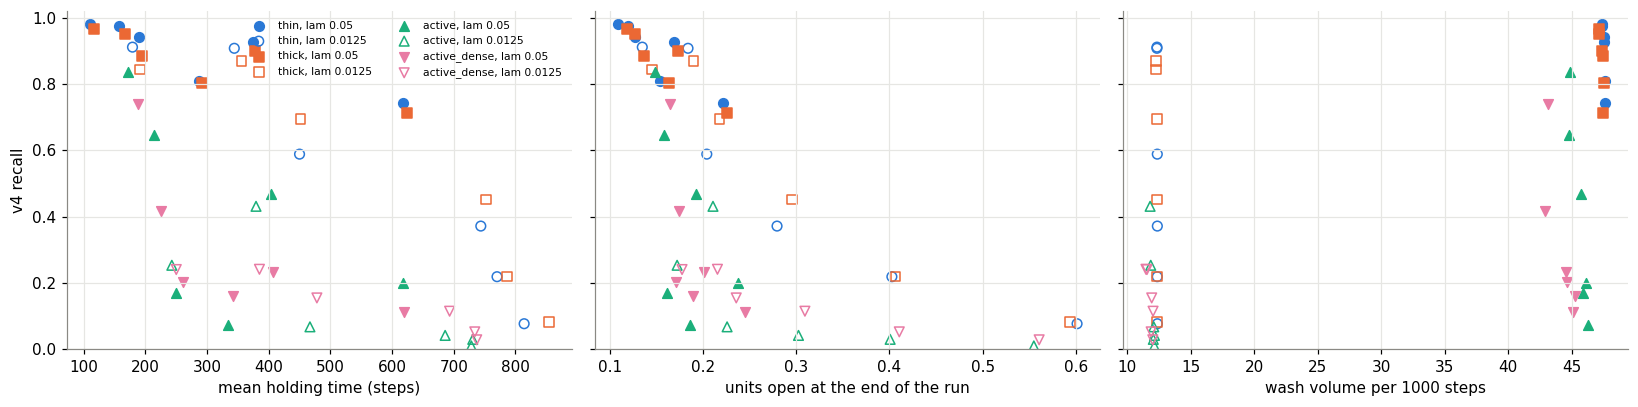

In [8]:
cell = aw[(aw.f_gap == 0) & (aw.method == "v4")].groupby(
    ["background", "f_edge_order", "f_pipeline", "f_lam_wash"]).agg(
    recall=("trade_tp", "sum"), pos=("trade_pos", "sum"), hold=("hold_mean", "mean"),
    open_=("open_unit_share", "mean"), vol=("wash_volume_rate", "mean")).reset_index()
cell["recall"] = cell["recall"] / cell["pos"]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (col, lab) in zip(axes, [("hold", "mean holding time (steps)"),
                                 ("open_", "units open at the end of the run"),
                                 ("vol", "wash volume per 1000 steps")]):
    for b in BG4:
        for lam, fill in ((0.05, True), (0.0125, False)):
            s = cell[(cell.background == b) & (cell.f_lam_wash == lam)]
            ax.scatter(s[col], s["recall"], marker=MARKER[b], s=40,
                       facecolors=COLOR[b] if fill else "none", edgecolors=COLOR[b],
                       label=f"{b}, lam {lam}")
    ax.set_xlabel(lab)
axes[0].set_ylabel("v4 recall")
axes[0].legend(fontsize=7, ncol=2)
for ax in axes:
    ax.set_ylim(0, 1.02)
fig.tight_layout()
display(aw[(aw.f_gap == 0) & (aw.method == "v4") & (aw.background == "active")]
        .groupby(["f_lam_wash", "f_edge_order", "f_pipeline"])[
            ["repeat_share_50", "hold_mean", "open_unit_share", "rounds_completed_share",
             "wash_volume_rate"]].mean().round(2))

## 7. Gap 5

The same as section 4 at gap 5. At gap 5 the v7 execution was already almost undetectable in
the active markets (detection v4); the table shows what is left in thin and thick.

In [9]:
s = aw[(aw.f_gap == 5) & (aw.method == "v4")]
p = pooled(s, ["f_lam_wash", "f_edge_order", "f_pipeline", "background"])["recall"].unstack("background")[BG4]
display(p.round(2))

background                          thin  thick  active  active_dense
f_lam_wash f_edge_order f_pipeline                                   
0.0125     interleaved  1.0         0.85   0.71    0.06          0.04
                        4.0         0.47   0.50    0.00          0.05
                        8.0         0.31   0.31    0.01          0.04
           sequential   1.0         0.81   0.65    0.04          0.02
                        4.0         0.14   0.13    0.00          0.01
                        8.0         0.06   0.05    0.00          0.01
0.0500     interleaved  1.0         0.97   0.91    0.40          0.27
                        4.0         0.89   0.73    0.02          0.05
                        8.0         0.67   0.67    0.02          0.06
           sequential   1.0         0.96   0.83    0.08          0.06
                        4.0         0.83   0.65    0.04          0.02
                        8.0         0.38   0.32    0.01          0.02

## 8. Multi-unit honest orders (`honest` sweep, gap 0)

Recall, FPR in wash runs and AP of v4 and of the closure channel. In each pair of columns the
first value has order size 1 (ZI) and the second 1..4 (`_mu4`). "evasive" is v7's execution,
"evasive_block" sends one order of Q units per edge, and "evasive_ip8" is interleaved with
pipeline 8.

In [10]:
hn = R["honest"]
hw = hn[(hn["f_scenario"] != "control") & hn.method.isin(["closure", "roundtrip_100", "repeat_200", "v4"])]
p = pooled(hw, ["f_base", "f_scenario", "method", "f_honest_size"])
for met in ("recall", "fpr", "ap"):
    print(met)
    display(p[met].unstack(["method", "f_honest_size"])[["closure", "v4"]].reindex(BG4, level=0).round(2))

recall


method                     closure          v4      
f_honest_size                    1     4     1     4
f_base       f_scenario                             
thin         evasive          0.65  0.61  0.98  0.91
             evasive_block    0.78  0.74  0.99  0.98
             evasive_ip8      0.82  0.78  0.81  0.74
             triad            0.97  0.97  1.00  1.00
thick        evasive          0.69  0.48  0.95  0.87
             evasive_block    0.82  0.63  0.98  0.91
             evasive_ip8      0.83  0.61  0.80  0.47
             triad            0.97  0.97  1.00  1.00
active       evasive          0.08  0.00  0.65  0.40
             evasive_block    0.17  0.00  0.91  0.68
             evasive_ip8      0.16  0.00  0.07  0.00
             triad            0.46  0.00  1.00  1.00
active_dense evasive          0.13  0.00  0.42  0.22
             evasive_block    0.26  0.00  0.89  0.59
             evasive_ip8      0.22  0.00  0.16  0.00
             triad            0.52  0.00  1.00  1.00

fpr


method                     closure          v4      
f_honest_size                    1     4     1     4
f_base       f_scenario                             
thin         evasive          0.05  0.04  0.07  0.06
             evasive_block    0.17  0.14  0.23  0.21
             evasive_ip8      0.10  0.07  0.09  0.06
             triad            0.01  0.03  0.02  0.02
thick        evasive          0.04  0.02  0.04  0.02
             evasive_block    0.13  0.08  0.13  0.08
             evasive_ip8      0.08  0.03  0.05  0.02
             triad            0.03  0.01  0.03  0.02
active       evasive          0.00  0.00  0.00  0.00
             evasive_block    0.00  0.00  0.02  0.01
             evasive_ip8      0.00  0.00  0.00  0.00
             triad            0.02  0.00  0.03  0.02
active_dense evasive          0.00  0.00  0.00  0.00
             evasive_block    0.01  0.00  0.01  0.01
             evasive_ip8      0.00  0.00  0.00  0.00
             triad            0.03  0.00  0.03  0.01

ap


method                     closure          v4      
f_honest_size                    1     4     1     4
f_base       f_scenario                             
thin         evasive          0.95  0.95  0.94  0.98
             evasive_block    0.96  0.96  0.97  0.96
             evasive_ip8      0.95  0.96  0.95  0.96
             triad            1.00  1.00  1.00  1.00
thick        evasive          0.92  0.88  0.98  0.97
             evasive_block    0.96  0.93  0.98  0.97
             evasive_ip8      0.93  0.90  0.93  0.88
             triad            1.00  1.00  1.00  1.00
active       evasive          0.53  0.35  0.89  0.92
             evasive_block    0.74  0.46  0.96  0.89
             evasive_ip8      0.64  0.49  0.47  0.13
             triad            0.95  0.77  0.97  1.00
active_dense evasive          0.38  0.23  0.89  0.88
             evasive_block    0.65  0.32  0.95  0.82
             evasive_ip8      0.50  0.38  0.34  0.07
             triad            0.92  0.69  0.98  0.99

## 9. Summary (200 seeds per cell; pooled control FPR 1%, floor 0.5)

1. **Interleaving alone does not evade v4.** It removes most same-pair bursts (repeat share
   within 50 steps 0.85 → 0.48). But each wallet then undoes its position after one pass of the
   cycle, which the round-trip channel catches. Active recall rises (0.65 → 0.84).
2. **A pipeline does evade v4 in the active markets.** At wash rate 0.05, recall falls from
   0.65 to 0.47 / 0.20 with sequential edges (D = 4 / 8), and to 0.17 / 0.07 with interleaved
   edges. A slower rate alone is not enough (0.43 sequential, 0.25 interleaved, at D = 1).
   Combined with a pipeline it gives 0.01–0.07 (active) and 0.03–0.15 (active_dense). FPR stays
   near 0. In thin and thick, v4 keeps 0.71–0.98 at rate 0.05, but a slow sequential pipeline
   brings it to 0.08–0.22 there too.
3. **The cost of the pipeline is small.** Wash volume is unchanged (about 46 per 1000 steps).
   With D = 8, each wallet holds a unit for 310–620 steps instead of 150–190, and 45% of the
   rounds are still unfinished when the run ends. 17–23% of a wash wallet's units are open at the
   end, against 14% for v7's execution. The group as a whole stays flat. The per-wallet, short-window evidence that
   v4 added can therefore be removed cheaply. Holding risk at wallet level is the only price.
4. **Multi-unit honest orders weaken closure, not the new channels.** In active_mu4 and
   active_dense_mu4 the closure channel cannot reach a 1% control FPR and flags nothing. v4
   still catches the fixed triad (1.00) and block-executed rounds (0.68 / 0.59). Against v7
   execution its recall falls from 0.65 to 0.40 (active) and from 0.42 to 0.22 (active_dense).
5. **Next step.** The pipeline's weak point is the group: its wallets trade only with each other,
   and their summed position stays flat while each holds a position. That points to group-level
   evidence, such as closure measured on clusters of the counterparty graph rather than on single
   wallets.